# Athlete earnings 2012-2019: salaries, endorsements and who captures the money
**Data.** Forbes' annual lists of the world's highest-paid athletes, 2012-2019 (795 entries; 2014 lists only 55 names). Each entry gives total pay with salary/winnings and endorsements in $ millions, plus sport.

**Questions.** How fast did top-athlete pay grow, which sports dominate, and how does the salary vs endorsement mix differ by sport? Endorsement income is the closest thing to a measure of an athlete's *brand* value, separate from on-field contracts. The finished chart is an animated bar-chart race.

In [1]:
import warnings, pathlib, os
warnings.filterwarnings("ignore"); os.environ["TF_CPP_MIN_LOG_LEVEL"] = "3"
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
pd.set_option("display.precision", 3)
plt.rcParams.update({"figure.figsize": (10, 4.5), "axes.grid": True, "grid.alpha": 0.3,
                     "axes.spines.top": False, "axes.spines.right": False, "figure.dpi": 110})
IMG = pathlib.Path("images"); IMG.mkdir(exist_ok=True)
f = pd.read_excel("data/forbes_highest_paid_athletes_2012_2019.xlsx")
def money(s):   # "$127 M" -> 127.0 ; "$500 K" -> 0.5 ($ millions)
    s = s.astype(str).str.replace(r"[$,\s]", "", regex=True)
    v = pd.to_numeric(s.str.rstrip("MK"), errors="coerce")
    return np.where(s.str.endswith("K"), v / 1000, v)
f["pay"], f["salary"], f["endorse"] = money(f.Pay), money(f["Salary/Winnings"]), money(f.Endorsements)
f["rank"] = pd.to_numeric(f.Rank.astype(str).str.lstrip("#"), errors="coerce")
f["Sport"] = f.Sport.replace({"Auto Racing": "Racing", "Football": "American football"})
chk = (f.salary + f.endorse - f.pay).abs()
bad = f[f.pay <= 0]; f = f[f.pay > 0]   # one 2015 record is listed as $0 M: a data error
print(f"dropped {len(bad)} record(s) with zero pay: {bad.Name.tolist()}")
print(f"{len(f)} entries; parse failures: {f[['pay', 'salary', 'endorse']].isna().sum().to_dict()}; rows where salary + endorsements ≠ pay (> $0.2m): {(chk > .2).sum()}")
f.head()

dropped 1 record(s) with zero pay: ['Russell Westbrook']
794 entries; parse failures: {'pay': 0, 'salary': 0, 'endorse': 0}; rows where salary + endorsements ≠ pay (> $0.2m): 1


,Rank,Name,Pay,Salary/Winnings,Endorsements,Sport,Year,pay,salary,endorse,rank
0,#1,Lionel Messi,$127 M,$92 M,$35 M,Soccer,2019,127.0,92.0,35.0,1
1,#2,Cristiano Ronaldo,$109 M,$65 M,$44 M,Soccer,2019,109.0,65.0,44.0,2
2,#3,Neymar,$105 M,$75 M,$30 M,Soccer,2019,105.0,75.0,30.0,3
3,#4,Canelo Alvarez,$94 M,$92 M,$2 M,Boxing,2019,94.0,92.0,2.0,4
4,#5,Roger Federer,$93.4 M,$7.4 M,$86 M,Tennis,2019,93.4,7.4,86.0,5


In [2]:
top100 = f[f.Year != 2014]
yr = top100.groupby("Year").agg(entries=("pay", "size"), total_pay_bn=("pay", lambda x: x.sum() / 1e3), median=("pay", "median"), cutoff=("pay", "min"),
                                 endorse_share=("endorse", lambda x: 100 * x.sum() / top100.loc[x.index, "pay"].sum()))
yr.round(2)

,entries,total_pay_bn,median,cutoff,endorse_share
Year,,,,,
2012,100,2.60,21.95,16.6,27.07
2013,100,2.62,22.15,16.4,29.92
2015,109,3.45,23.70,18.8,25.17
2016,110,3.39,25.65,20.8,27.60
2017,110,3.37,26.60,21.4,27.82
2018,110,4.05,27.90,22.9,21.87
2019,100,4.00,31.60,25.0,24.67


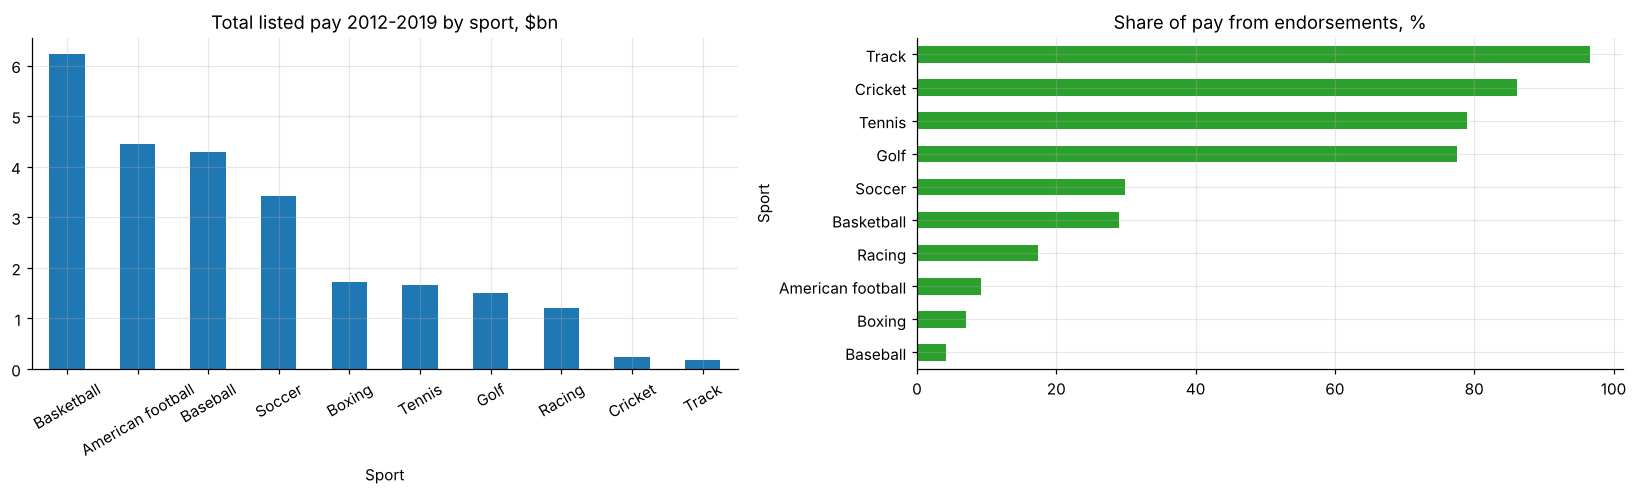

,entries,total,endorse,athletes,endorse_share_%
Sport,,,,,
Basketball,199,6234.0,1812.4,63,29.1
American football,148,4443.9,405.9,101,9.1
Baseball,178,4289.0,177.2,58,4.1
Soccer,93,3415.9,1018.0,34,29.8
Boxing,28,1728.3,122.3,8,7.1
Tennis,45,1655.8,1307.0,8,78.9
Golf,38,1505.5,1166.5,12,77.5
Racing,41,1212.8,211.3,10,17.4
Cricket,9,230.6,198.5,3,86.1


In [3]:
sp = f.groupby("Sport").agg(entries=("pay", "size"), total=("pay", "sum"), endorse=("endorse", "sum"), athletes=("Name", "nunique"))
sp["endorse_share_%"] = 100 * sp.endorse / sp.total; sp = sp[sp.entries >= 7].sort_values("total", ascending=False)
fig, axes = plt.subplots(1, 2, figsize=(15, 4.6))
(sp.total / 1e3).plot.bar(ax=axes[0], rot=30, title="Total listed pay 2012-2019 by sport, $bn")
sp["endorse_share_%"].sort_values().plot.barh(ax=axes[1], color="C2", title="Share of pay from endorsements, %")
plt.tight_layout(); plt.savefig(IMG / "sports.png", bbox_inches="tight"); plt.show()
sp.round(1)

In [4]:
ath = f.groupby("Name").agg(sport=("Sport", "first"), years=("Year", "nunique"), total=("pay", "sum"), endorse=("endorse", "sum")).sort_values("total", ascending=False)
ath["endorse_share_%"] = 100 * ath.endorse / ath.total
share_top10 = ath.total.head(10).sum() / ath.total.sum() * 100
print(f"{len(ath)} different athletes; the top 10 by cumulative pay took {share_top10:.0f}% of all listed pay")
ath.head(10).round(1)

300 different athletes; the top 10 by cumulative pay took 20% of all listed pay


,sport,years,total,endorse,endorse_share_%
Name,,,,,
Floyd Mayweather,Boxing,6,853.0,37.0,4.3
Cristiano Ronaldo,Soccer,8,652.5,261.0,40.0
Lionel Messi,Soccer,8,625.8,208.0,33.2
LeBron James,Basketball,8,587.8,393.0,66.9
Roger Federer,Tennis,8,549.8,489.0,88.9
Tiger Woods,Golf,8,438.9,403.0,91.8
Phil Mickelson,Golf,8,386.6,346.0,89.5
Kevin Durant,Basketball,7,350.1,199.0,56.8
Manny Pacquiao,Boxing,6,347.8,31.3,9.0


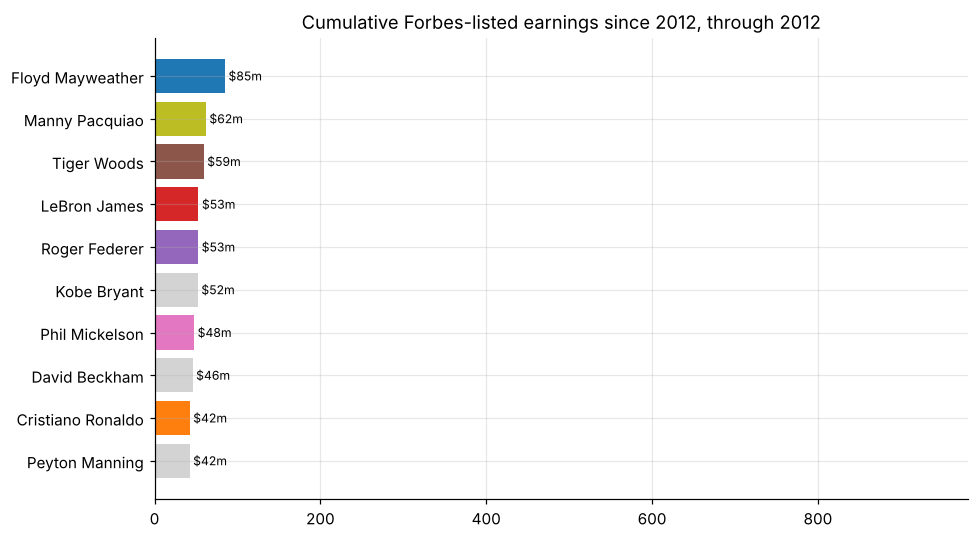

In [5]:
import matplotlib.animation as animation
years = sorted(f.Year.unique()); cum = f.pivot_table(index="Year", columns="Name", values="pay", aggfunc="sum").fillna(0).cumsum()
top_names = cum.iloc[-1].nlargest(10).index; colors = dict(zip(top_names, plt.cm.tab10.colors))
fig, ax = plt.subplots(figsize=(9, 5))
def frame(i):
    ax.clear(); y = years[i]; s = cum.loc[y].nlargest(10)[::-1]
    ax.barh(s.index, s.values, color=[colors.get(n, "lightgrey") for n in s.index])
    for n, v in s.items(): ax.text(v, n, f" ${v:,.0f}m", va="center", fontsize=8)
    ax.set_title(f"Cumulative Forbes-listed earnings since 2012, through {y}"); ax.set_xlim(0, cum.values.max() * 1.15)
    ax.spines[["top", "right"]].set_visible(False)
anim = animation.FuncAnimation(fig, frame, frames=len(years), interval=900)
anim.save(IMG / "earnings_race.gif", writer=animation.PillowWriter(fps=1.2)); frame(len(years) - 1)
plt.tight_layout(); plt.savefig(IMG / "earnings_final.png", bbox_inches="tight"); plt.show()

## Findings
* **Top-athlete pay rose 54% in seven years.** The 100 best-paid athletes earned a combined $2.6bn in 2012 and $4.0bn in 2019. The entry ticket to the list rose from $16.6m to $25.0m and the median from $22m to $32m. (2014 is excluded from year comparisons because only 55 names were published.)
* **Endorsements are about a quarter of the total** (22-30% a year), but the mix depends heavily on the sport. Individual "brand" sports earn mostly from sponsors: track 97% (one athlete), cricket 86%, tennis 79%, golf 78%. Team sports with large salary pools earn mostly from contracts: baseball 4%, boxing 7%, American football 9%.
* **US team sports dominate by volume** (basketball, American football and baseball make up 525 of 794 entries), while soccer's 34 athletes average far more per entry.
* **Two routes to the top:** Floyd Mayweather leads cumulative listed earnings ($853m) with only 4% from endorsements, while Roger Federer and Tiger Woods earned about 90% of their totals off the field. The top 10 athletes took 20% of all listed pay across 300 names.
* **Data quality:** amounts are quoted in "$ M" and "$ K" and needed unit-aware parsing, and one 2015 record lists $0 pay and was dropped. Forbes figures are estimates before tax and agents' fees.